In [2]:
import cv2
from matplotlib import pyplot as plt
import math
import copy

def signed_angle_to_vertical(p1, p2, degrees=True):
    x1, y1 = p1
    x2, y2 = p2

    dx = x2 - x1
    dy = y2 - y1

    if dx == 0 and dy == 0:
        raise ValueError("两点重合，无法确定直线")

    # 以竖直向上为 0°，向右偏为正，向左偏为负
    angle = math.atan2(dx, dy)

    return math.degrees(angle) if degrees else angle


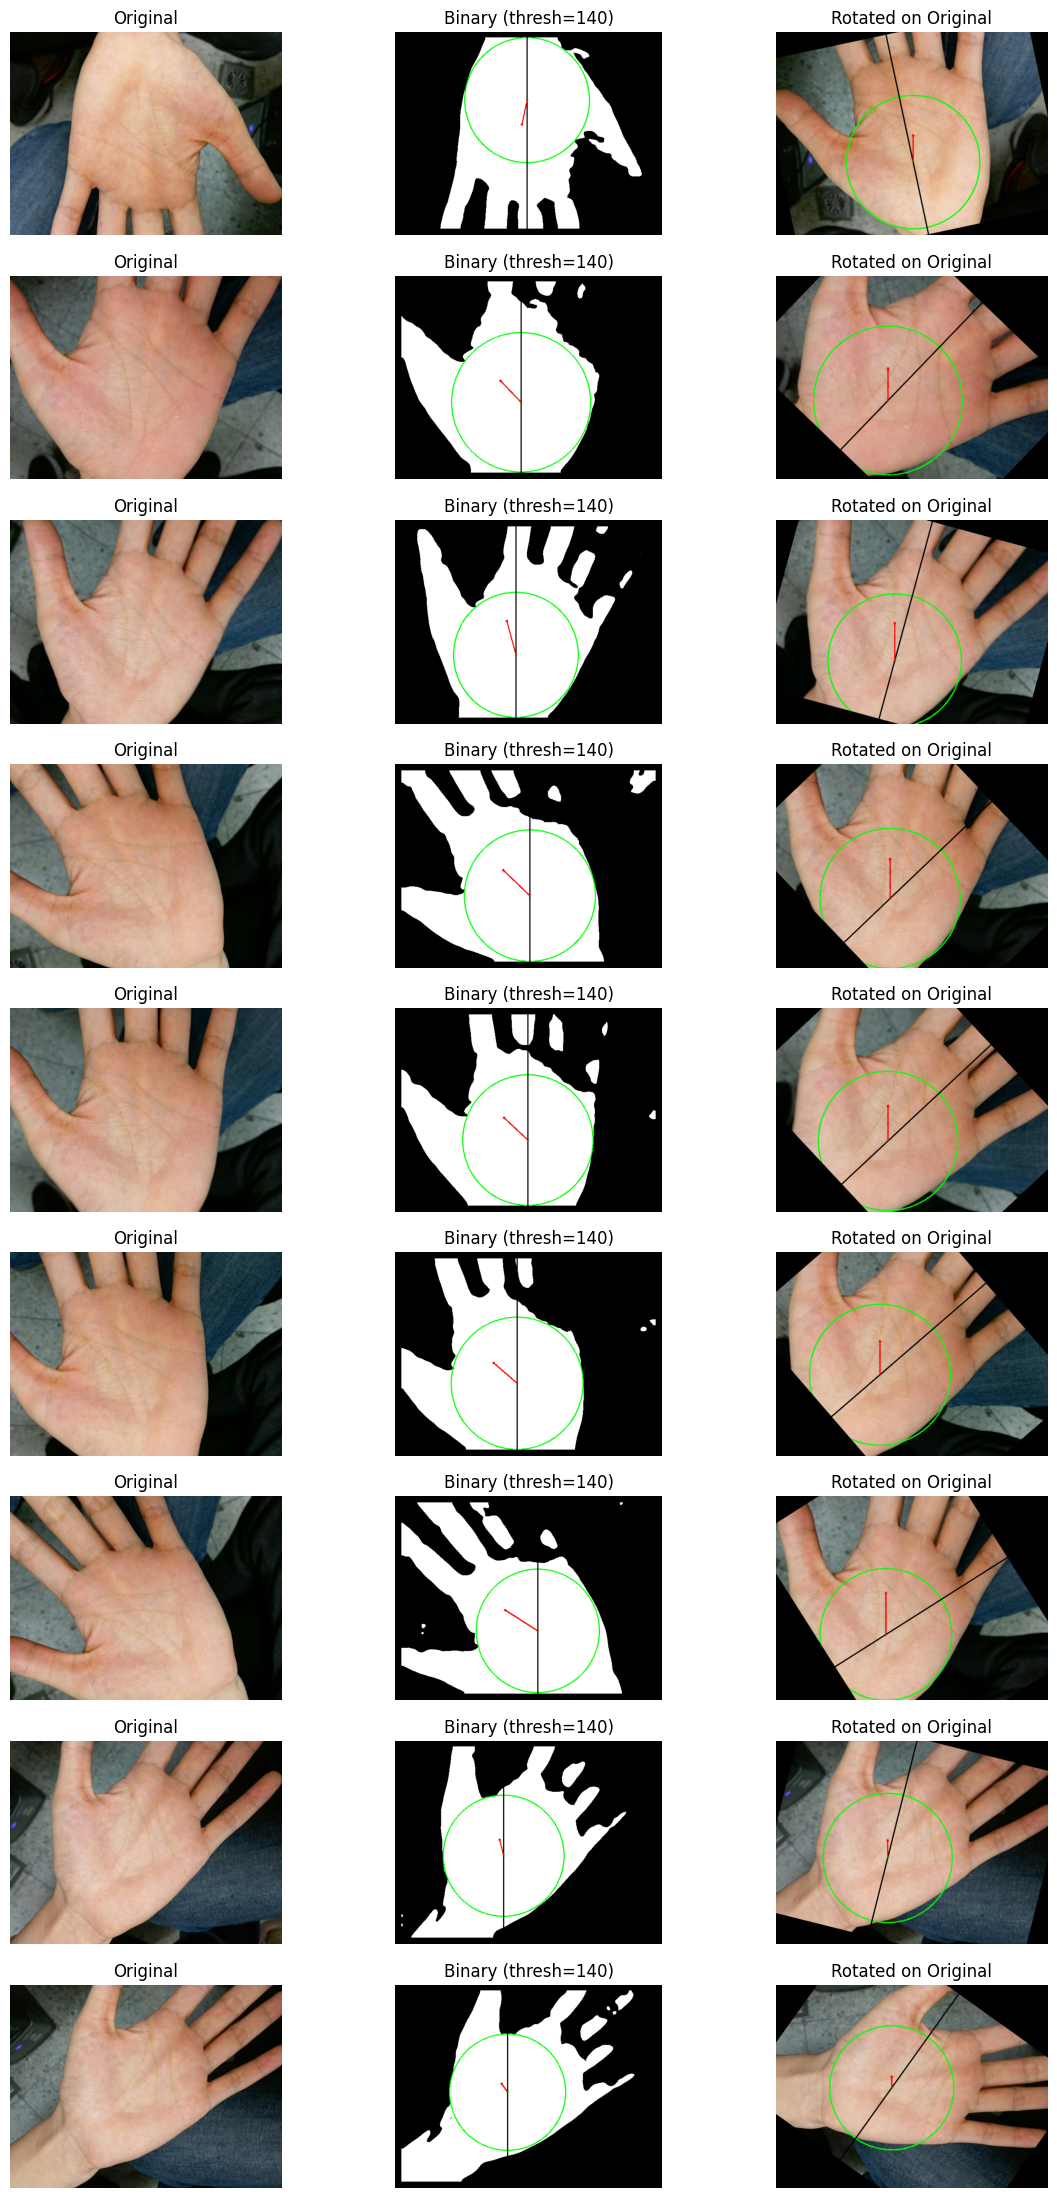

In [57]:
plt.figure(figsize=(14, 28))
for i in range(1,10):
    img = cv2.imread(f'../Images/200_samples/ntust-hp/0003/0{i:d}.png')
    
    # img = img / cv2.GaussianBlur(img, (0,0), 1)
    img_gaus = cv2.GaussianBlur(img, (31, 31), 0)
    img_gaus_rgb = cv2.cvtColor(img_gaus, cv2.COLOR_BGR2RGB)
    img_gaus_gray = cv2.cvtColor(img_gaus, cv2.COLOR_BGR2GRAY)
    ret, img_gaus_gray_binary = cv2.threshold(
        img_gaus_gray, 
        thresh=140,
        maxval=255, 
        type=cv2.THRESH_BINARY # + cv2.THRESH_OTSU
    )
    # ret=0.1
    # img_gaus_gray_binary = cv2.adaptiveThreshold(img_gaus_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 161, 0)
    
    # kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (16, 16))
    # img_gaus_gray_binary_eroded = cv2.erode(img_gaus_gray_binary, kernel, iterations=1)
    # img_gaus_gray_binary_eroded_dilated = cv2.dilate(img_gaus_gray_binary_eroded, kernel, iterations=1)
    img_gaus_gray_binary_eroded_dilated = img_gaus_gray_binary
    
    img_gaus_gray_binary_eroded_dilated = cv2.copyMakeBorder(img_gaus_gray_binary_eroded_dilated, 16, 16, 16, 16, cv2.BORDER_CONSTANT, value=0)
    
    dist_transform = cv2.distanceTransform(img_gaus_gray_binary_eroded_dilated, cv2.DIST_L2, 5)
    _, max_val, _, max_loc = cv2.minMaxLoc(dist_transform)
    
    M = cv2.moments(img_gaus_gray_binary, binaryImage=True)
    cx = int(M["m10"] / M["m00"])
    cy = int(M["m01"] / M["m00"])
    
    radius = dist_transform[cy, cx]
    
    def vis(img):
        if len(img.shape) == 2:
            img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
        else:
            img = copy.deepcopy(img)
        cv2.circle(img, (cx, cy), 3, (0, 0, 255), -1)
        
        cv2.circle(img, max_loc, int(max_val), (0, 255, 0), 2)
        cv2.circle(img, max_loc, 3, (0, 255, 0), -1)
        
        y, x = img.shape[:2]
        cv2.line(img, max_loc, (max_loc[0],0), (0,0,0), 2)
        cv2.line(img, max_loc, (max_loc[0],y), (0,0,0), 2)
        cv2.line(img, max_loc, (cx, cy), (0,0,255), 2)
    
        return img
    
    img_gaus_gray_binary_eroded_dilated_vis = vis(img_gaus_gray_binary_eroded_dilated)
    img_vis = vis(img)
    
    
    
    rows, cols = img.shape[:2]
    
    
    center = (cols / 2, rows / 2)
    angle = -signed_angle_to_vertical((cx, cy), max_loc)
    scale = 1.0
    
    
    M = cv2.getRotationMatrix2D(center, angle, scale)
    
    
    
    plt.subplot(9, 3, 1+(i-1)*3)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"Original")
    plt.axis('off')
    
    plt.subplot(9, 3, 2+(i-1)*3)
    
    plt.imshow(cv2.cvtColor(img_gaus_gray_binary_eroded_dilated_vis, cv2.COLOR_BGR2RGB))
    plt.title(f'Binary (thresh={ret:.0f})')
    plt.axis('off')
    
    plt.subplot(9, 3, 3+(i-1)*3)
    img_vis_rotated = cv2.warpAffine(img_vis, M, (cols, rows))
    plt.imshow(cv2.cvtColor(img_vis_rotated, cv2.COLOR_BGR2RGB))
    plt.title(f"Rotated on Original")
    plt.axis('off')
    
# plt.tight_layout()
plt.show()
